# 2r_age_groups: population by age group in the affected municipalities, 2011 and 2016 earthquakes

One panel per affected municipality, one figure per prefecture, for the municipalities listed in `dt/analysis_original_data.xlsx` (sheet `1_市町村一覧`):

| Disaster | 災害 groups | Prefectures (municipalities) | Years |
|---|---|---|---|
| 2016 Kumamoto Earthquake | 熊本 | 熊本 45 | 2011–2021 |
| 2011 Great East Japan Earthquake | 東日本, 福島 | 岩手 33, 宮城 34, 福島 56 | 2006–2016 |

Each window is ±5 years around the disaster year. Noto (2024) is left out because its data only run to 2026.

- **Figures 1–4 (age groups):** four age groups (0–19, 20–39, 40–64, 65+) on the left axis, and the total population as a dark line on the right axis.
- **Figures 5–8 (change rate):** year-on-year % change for the same groups and the total, all on one axis.
- **Panels:** sorted by 全壊率 (fully destroyed buildings per 100 residents; the number after each name), highest first. **†** marks municipalities with an evacuation order (`避難指示あり`; 10 in Fukushima).
- **Data:** `dt/jumin_age_sex_5yr_long.qs2`, built by `src/build_jumin_age.R` (住民基本台帳, e-Stat). Japanese residents (`basis == "japanese"`), both sexes. Age groups are sums of the 5-year bands; 65+ includes 80+.
- **Timing:** counts are as of 31 March up to 2012 and 1 January from 2013, so the 2012→2013 step covers 9 months.
  - Great East Japan (2011-03-11): falls between the 2010 and 2011 counts; the 2011 count is from 20 days after it.
  - Kumamoto (2016-04-14/16): falls between the 2016 and 2017 counts.
- **Values:** raw counts. Each panel has its own axes, so compare shapes across panels, not heights.
- **Right axis:** ggplot allows one secondary-axis transform for all panels, so the total is drawn divided by a fixed factor (`k_total`, 1.5) and the right axis multiplies back. The right-axis labels are correct in every panel. Read each line against its own axis; where the dark line sits relative to the coloured ones means nothing.
- **Resident registration:** evacuees who did not move their 住民票 still count as residents, so the population loss in evacuated municipalities is understated (see `doc/caution.md`).
- **Saved outputs:** each figure is also written to `res/` as `2r_<NN>_<item>.png`, via `show_save()`. Tables are shown here only.

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
}))
options(repr.plot.width = 17, repr.plot.height = 13, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

# The notebook lives in src/; resolve the repo root so paths work from either.
root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
jp_font <- "Noto Sans CJK JP"   # conda font-ttf-noto-cjk (pinned in the Dockerfile)

# Saved figures are prefixed with this notebook's index, e.g. res/2r_01_....png
nb_prefix <- "2r_"
show_save <- function(p, name, width = 17, height = 13) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}

# One entry per disaster. event_x is where the dashed line goes (between the
# last count before and the first count after); base_year is the last count
# before the disaster, used in the summary table.
events <- list(
  kumamoto = list(title = "2016 Kumamoto Earthquake", groups = "熊本",
                  years = 2011:2021, event_year = 2016, event_x = 2016.5,
                  base_year = 2016,
                  rate_note = "its first effect shows in the 2017 point"),
  tohoku   = list(title = "2011 Great East Japan Earthquake", groups = c("東日本", "福島"),
                  years = 2006:2016, event_year = 2011, event_x = 2010.5,
                  base_year = 2010,
                  rate_note = "the 2011 point, counted 20 days after it, already includes some of its effect")
)
group_event <- unlist(lapply(names(events), function(e)
  setNames(rep(e, length(events[[e]]$groups)), events[[e]]$groups)))

pop <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2"))

In [2]:
# Affected municipalities: listed under the events' 災害 groups in the workbook
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 %in% names(group_event)) |>
  transmute(event = unname(group_event[災害]), code = 市町村コード, muni = 市町村,
            pref = 県, short = sub("^.*郡", "", 市町村),   # 牡鹿郡女川町 -> 女川町
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`),
            evacuation = 避難指示あり %in% c("TRUE", "True", "1"))

age_groups <- list(
  "0–19"  = c("0_4", "5_9", "10_14", "15_19"),
  "20–39" = c("20_24", "25_29", "30_34", "35_39"),
  "40–64" = c("40_44", "45_49", "50_54", "55_59", "60_64"),
  "65+"   = c("65_69", "70_74", "75_79", "80+")
)
band_to_group <- setNames(rep(names(age_groups), lengths(age_groups)), unlist(age_groups))
groups_all <- c(names(age_groups), "Total")

# Population per municipality x year x group (Total + four age groups), over
# each event's window plus the year before (needed for the change rate).
d_all <- pop |>
  filter(code %in% study$code, basis == "japanese", sex == "計") |>
  mutate(age_band = as.character(age_band)) |>
  filter(age_band == "total" | age_band %in% names(band_to_group)) |>
  mutate(group = ifelse(age_band == "total", "Total", band_to_group[age_band])) |>
  group_by(code, year, group) |>
  summarise(pop = sum(pop), .groups = "drop") |>
  inner_join(study, by = "code") |>
  filter(mapply(function(e, y) y %in% (min(events[[e]]$years) - 1):max(events[[e]]$years),
                event, year))

d <- d_all |>
  filter(mapply(function(e, y) y %in% events[[e]]$years, event, year)) |>
  mutate(group = factor(group, levels = groups_all))

# Check: every municipality has every year and group; the four groups sum to
# the total; and the largest age-group share (sets the right-axis factor)
chk <- d |>
  group_by(event, pref, code, year) |>
  summarise(total = pop[group == "Total"], groups = sum(pop[group != "Total"]),
            max_group = max(pop[group != "Total"]), .groups = "drop")
chk |>
  group_by(event, pref) |>
  summarise(municipalities = n_distinct(code),
            evacuation_order = sum(study$evacuation[study$pref == first(pref)]),
            years = paste(range(year), collapse = "–"),
            rows_expected = municipalities * n_distinct(year) * 5,
            rows = 5 * n(),
            groups_differ_from_total = sum(total != groups),
            max_group_share = round(max(max_group / total), 3), .groups = "drop") |>
  as.data.frame()

event,pref,municipalities,evacuation_order,years,rows_expected,rows,groups_differ_from_total,max_group_share
<chr>,<chr>,<int>,<int>,<chr>,<dbl>,<dbl>,<int>,<dbl>
kumamoto,熊本県,45,0,2011–2021,2475,2475,0,0.492
tohoku,宮城県,34,0,2006–2016,1870,1870,0,0.465
tohoku,岩手県,33,0,2006–2016,1815,1815,0,0.451
tohoku,福島県,56,10,2006–2016,3080,3080,0,0.581


In [3]:
# Summary per municipality: change in each age group and the total from the
# last count before the disaster to the last year of the window, ordered by
# 全壊率 within each prefecture
bind_rows(lapply(names(events), function(e) {
  ev <- events[[e]]
  d |>
    filter(event == e, year %in% c(ev$base_year, max(ev$years))) |>
    mutate(when = ifelse(year == ev$base_year, "before", "after")) |>
    select(pref, short, zenkai_rate, evacuation, group, when, pop) |>
    pivot_wider(names_from = when, values_from = pop) |>
    mutate(change = sprintf("%+.1f%%", 100 * (after / before - 1)),
           period = sprintf("%d→%d", ev$base_year, max(ev$years))) |>
    select(pref, period, short, zenkai_rate, evacuation, group, change)
})) |>
  pivot_wider(names_from = group, values_from = change) |>
  arrange(desc(period), pref, desc(zenkai_rate)) |>
  mutate(zenkai_rate = round(zenkai_rate, 2)) |>
  rename(municipality = short, `全壊率` = zenkai_rate, `避難指示` = evacuation) |>
  as.data.frame()

pref,period,municipality,全壊率,避難指示,0–19,20–39,40–64,65+,Total
<chr>,<chr>,<chr>,<dbl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>
熊本県,2016→2021,益城町,8.75,FALSE,-1.7%,-16.2%,-6.9%,+8.7%,-3.8%
熊本県,2016→2021,西原村,7.25,FALSE,-7.5%,-19.4%,-9.3%,+9.9%,-5.6%
熊本県,2016→2021,南阿蘇村,5.98,FALSE,-19.0%,-31.7%,-16.3%,+5.2%,-11.7%
熊本県,2016→2021,嘉島町,2.54,FALSE,+12.8%,-4.0%,+4.2%,+7.9%,+5.0%
熊本県,2016→2021,御船町,2.51,FALSE,-1.4%,-13.0%,-10.4%,+5.2%,-4.4%
熊本県,2016→2021,甲佐町,0.94,FALSE,-2.7%,-19.6%,-10.3%,+1.6%,-6.5%
熊本県,2016→2021,宇城市,0.89,FALSE,-7.6%,-14.6%,-7.7%,+6.2%,-4.8%
熊本県,2016→2021,産山村,0.75,FALSE,-16.0%,-22.3%,-13.8%,-1.0%,-10.3%
熊本県,2016→2021,大津町,0.45,FALSE,+2.7%,-5.7%,+4.0%,+13.4%,+3.1%


In [4]:
# Shared look. The age groups take the reference palette's first four
# categorical slots in fixed order (blue, orange, aqua, yellow); the total is
# dark ink.
group_hex <- c("0–19" = "#2a78d6", "20–39" = "#eb6834", "40–64" = "#1baf7a", "65+" = "#eda100")
total_lab <- "Total (right axis)"
group_cols <- c(group_hex, "Total (right axis)" = "#2b2b29")
rate_cols  <- c(group_hex, "Total" = "#2b2b29")

# Secondary axis for the total: drawn divided by k and the right axis
# multiplies back by k. The largest age group is at most 58% of the total
# (an evacuated Fukushima municipality; 49% in Kumamoto), so k = 1.5
# (total/k = 67%) keeps the total line above every age-group line.
k_total <- 1.5
stopifnot(max(chk$max_group / chk$total) < 1 / k_total)

source_note <- paste0("Population: Basic Resident Register, e-Stat; Japanese residents, both sexes. ",
                      "Reference date 3/31 to 2012, 1/1 from 2013")

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#e6e5e1", linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = "#2b2b29", size = 9),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = "#5c5c58", size = 10),
    plot.caption = element_text(colour = "#8a8a85", size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = "#5c5c58", size = 7.5),
    axis.text.y.right = element_text(colour = "#2b2b29", size = 7.5),
    axis.title.y = element_text(colour = "#5c5c58", size = 10),
    axis.title.y.right = element_text(colour = "#2b2b29", size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  ),
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
)

# Panel labels "name† (全壊率)", ordered by 全壊率, highest first
panel_labels <- function(dd) {
  dd |>
    distinct(code, short, zenkai_rate, evacuation) |>
    arrange(desc(zenkai_rate), code) |>
    mutate(label = sprintf("%s%s (%.2f)", short, ifelse(evacuation, "†", ""), zenkai_rate))
}
pref_en <- c("岩手県" = "Iwate", "宮城県" = "Miyagi", "福島県" = "Fukushima", "熊本県" = "Kumamoto")
fig_title <- function(e, pref_name, what) {
  ev <- events[[e]]
  sprintf("%s, %s (%s): %s, %d–%d", ev$title, pref_en[[pref_name]], pref_name, what,
          min(ev$years), max(ev$years))
}
x_scale <- function(e) {
  ev <- events[[e]]
  scale_x_continuous(breaks = c(min(ev$years), ev$event_year, max(ev$years)))
}

plot_facets <- function(e, pref_name, ncol = 7) {
  dd <- d |> filter(event == e, pref == pref_name)
  lab <- panel_labels(dd)
  dd <- dd |>
    mutate(panel = factor(lab$label[match(code, lab$code)], levels = lab$label),
           is_total = group == "Total",
           y = ifelse(is_total, pop / k_total, pop),
           group = factor(ifelse(is_total, total_lab, as.character(group)),
                          levels = names(group_cols)))
  ggplot(dd, aes(year, y, colour = group)) +
    geom_vline(xintercept = events[[e]]$event_x, colour = "#8a8a85", linewidth = 0.4, linetype = "22") +
    geom_line(linewidth = 0.7) +
    geom_point(size = 0.9) +
    facet_wrap(~panel, ncol = ncol, scales = "free_y") +
    scale_colour_manual(values = group_cols, name = NULL) +
    x_scale(e) +
    scale_y_continuous(labels = scales::label_comma(), limits = c(0, NA),
                       expand = expansion(mult = c(0, 0.08)),
                       name = "Age groups (left axis)",
                       sec.axis = sec_axis(~ . * k_total, labels = scales::label_comma(),
                                           name = "Total population (right axis)")) +
    labs(
      title = fig_title(e, pref_name, "population by age group and total in each affected municipality"),
      subtitle = paste0(nrow(lab), " municipalities listed in the analysis data, ordered by 全壊率 ",
                        "(fully destroyed buildings per 100 residents; the number after each name).",
                        if (any(lab$evacuation)) " † = evacuation order (避難指示)." else "",
                        "\nRaw counts; each panel has its own axes. Age groups: left axis. Total (dark line): right axis, ",
                        "drawn at 1/", k_total, " of the left scale. Dashed line: the earthquake."),
      caption = paste0(source_note, " (the 2012→2013 step covers 9 months). ",
                       "Evacuees who kept their registration still count as residents."),
      x = NULL
    ) +
    base_theme()
}

## Age groups

### Figure 1: Kumamoto (熊本県), 45 municipalities

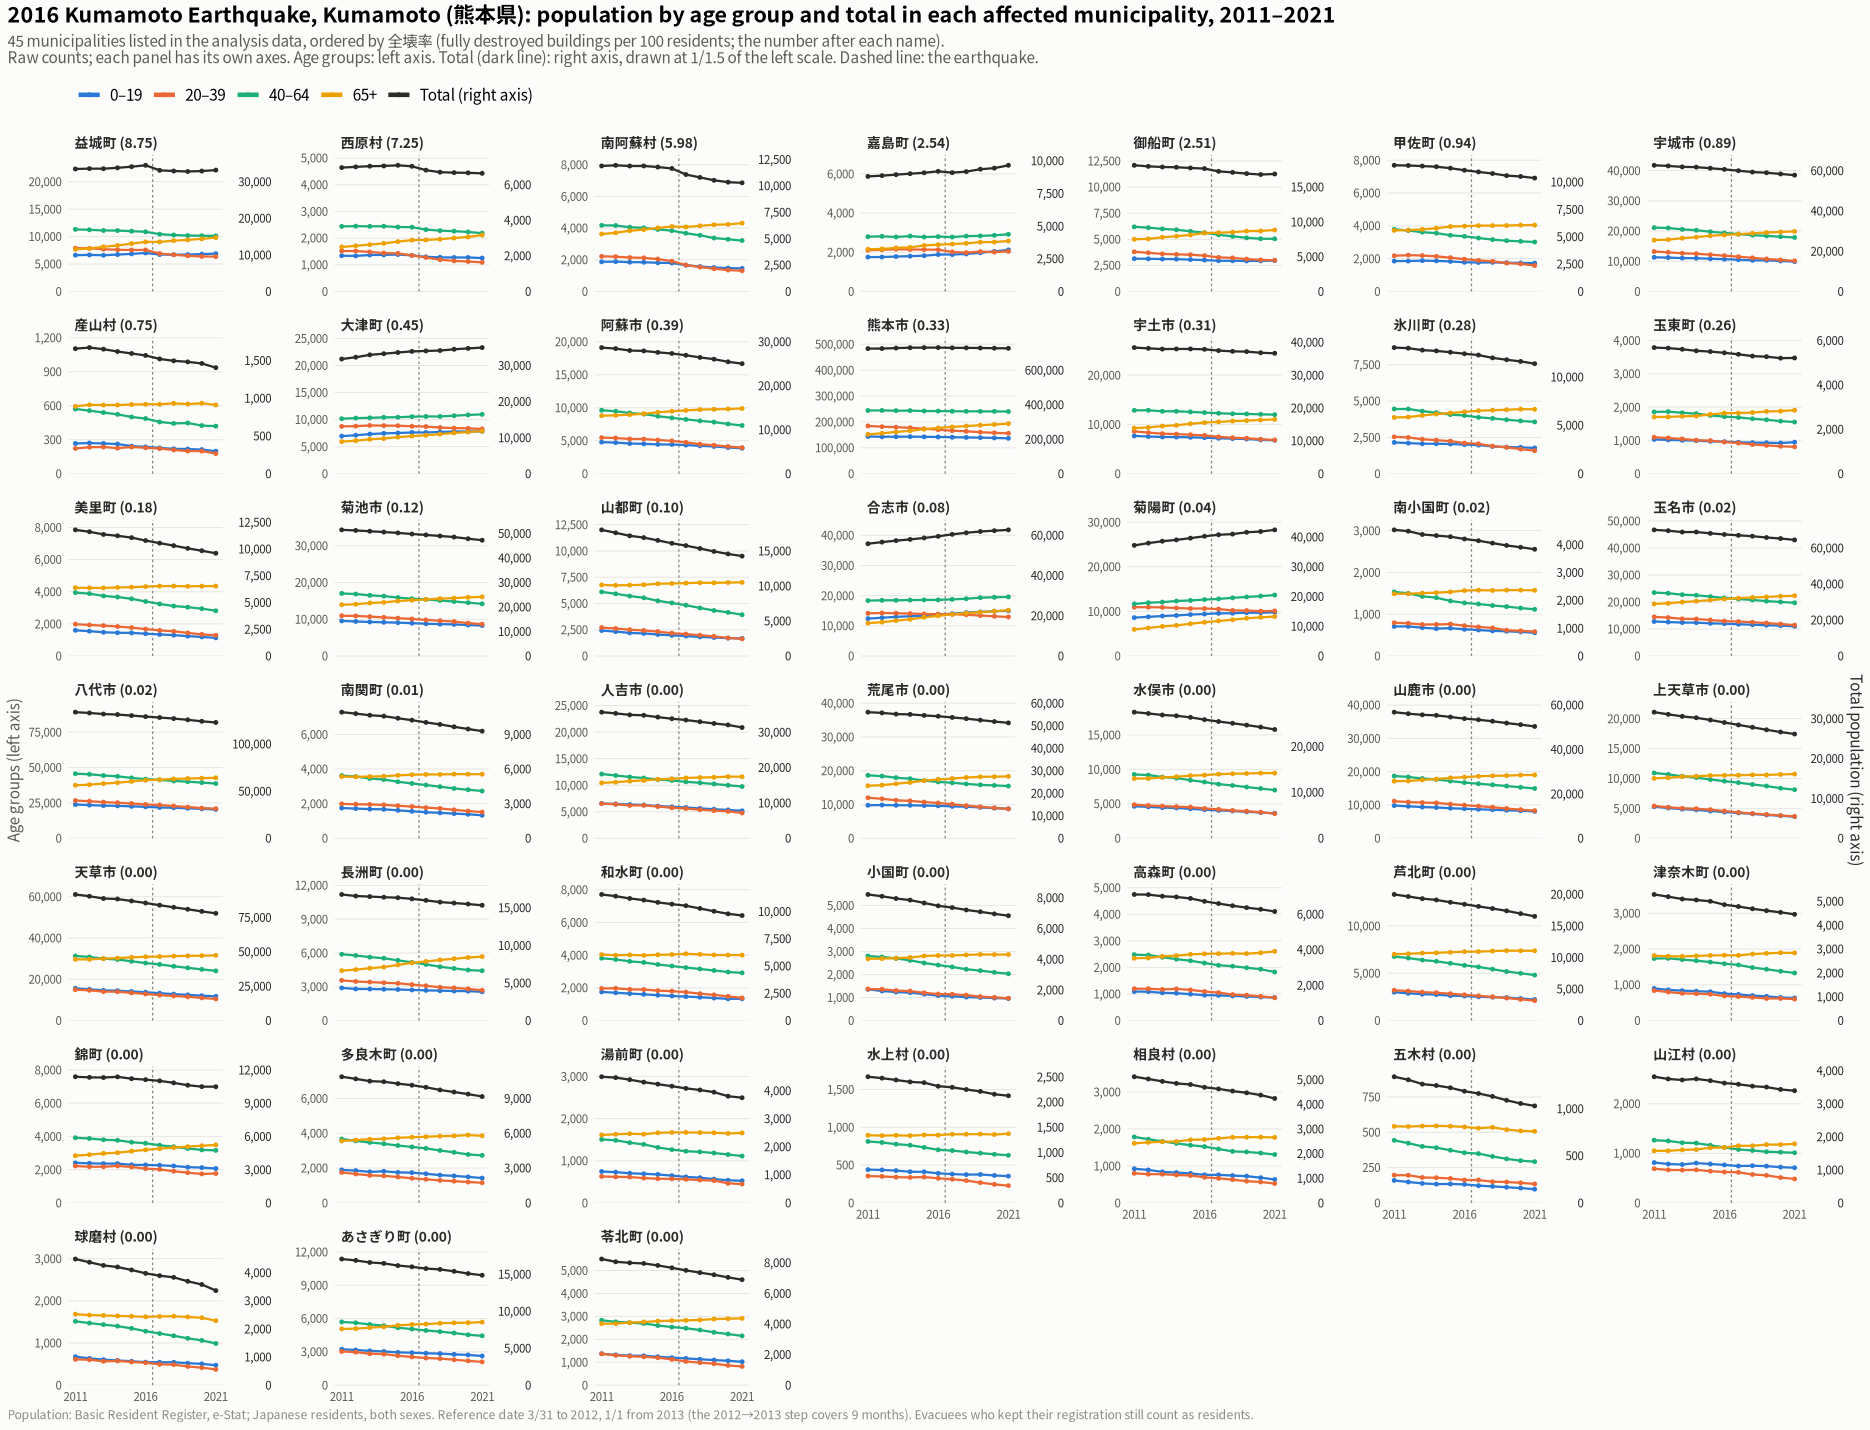

In [5]:
show_save(plot_facets("kumamoto", "熊本県"), "01_kumamoto_age_groups", width = 17, height = 13)

### Figure 2: Iwate (岩手県), 33 municipalities

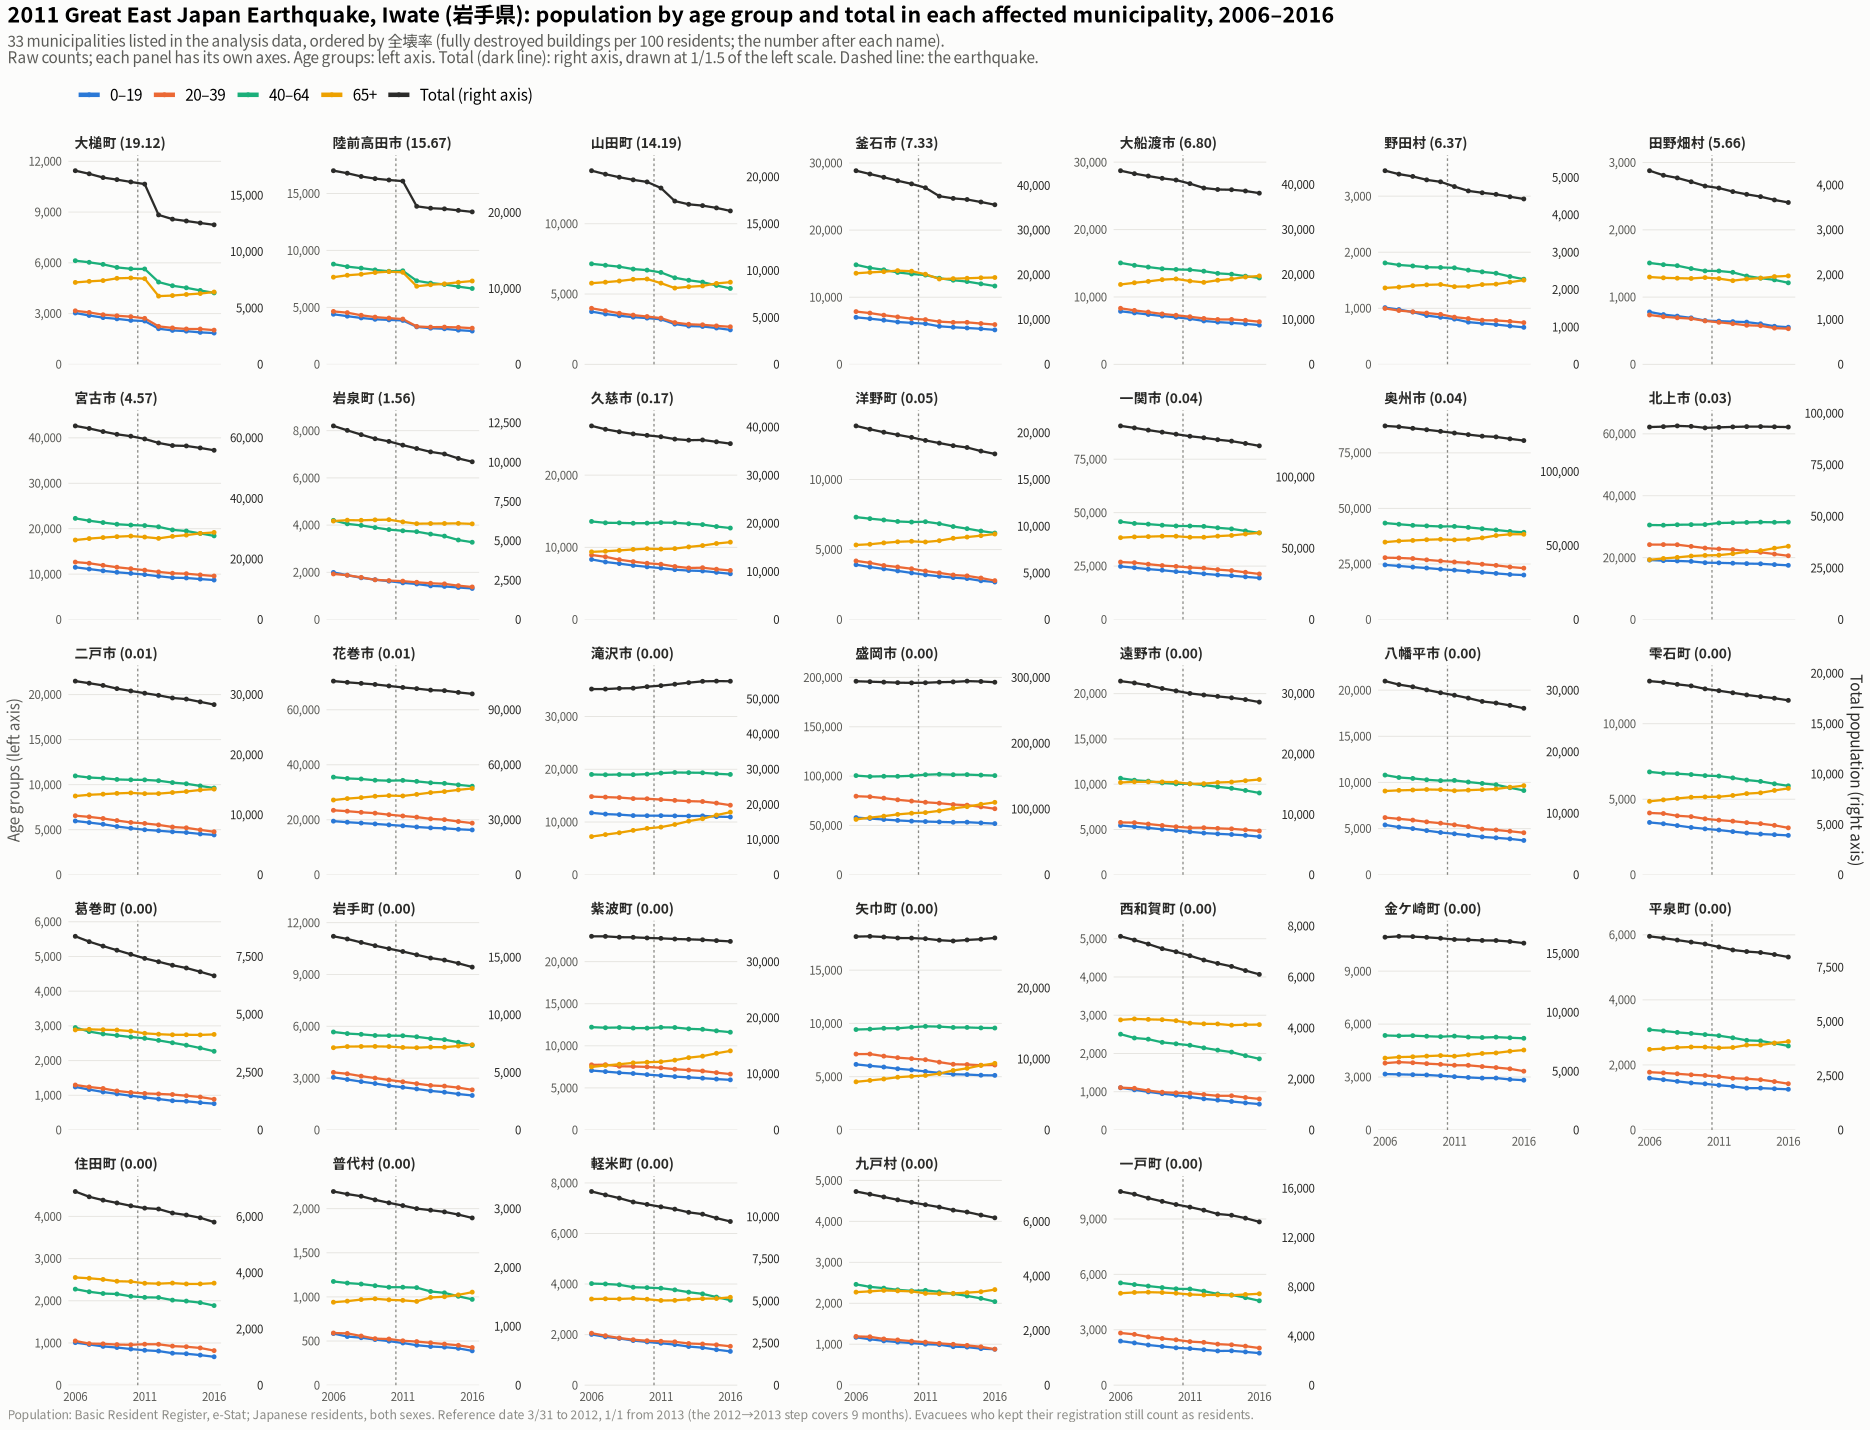

In [6]:
show_save(plot_facets("tohoku", "岩手県"), "02_iwate_age_groups", width = 17, height = 11)

### Figure 3: Miyagi (宮城県), 34 municipalities

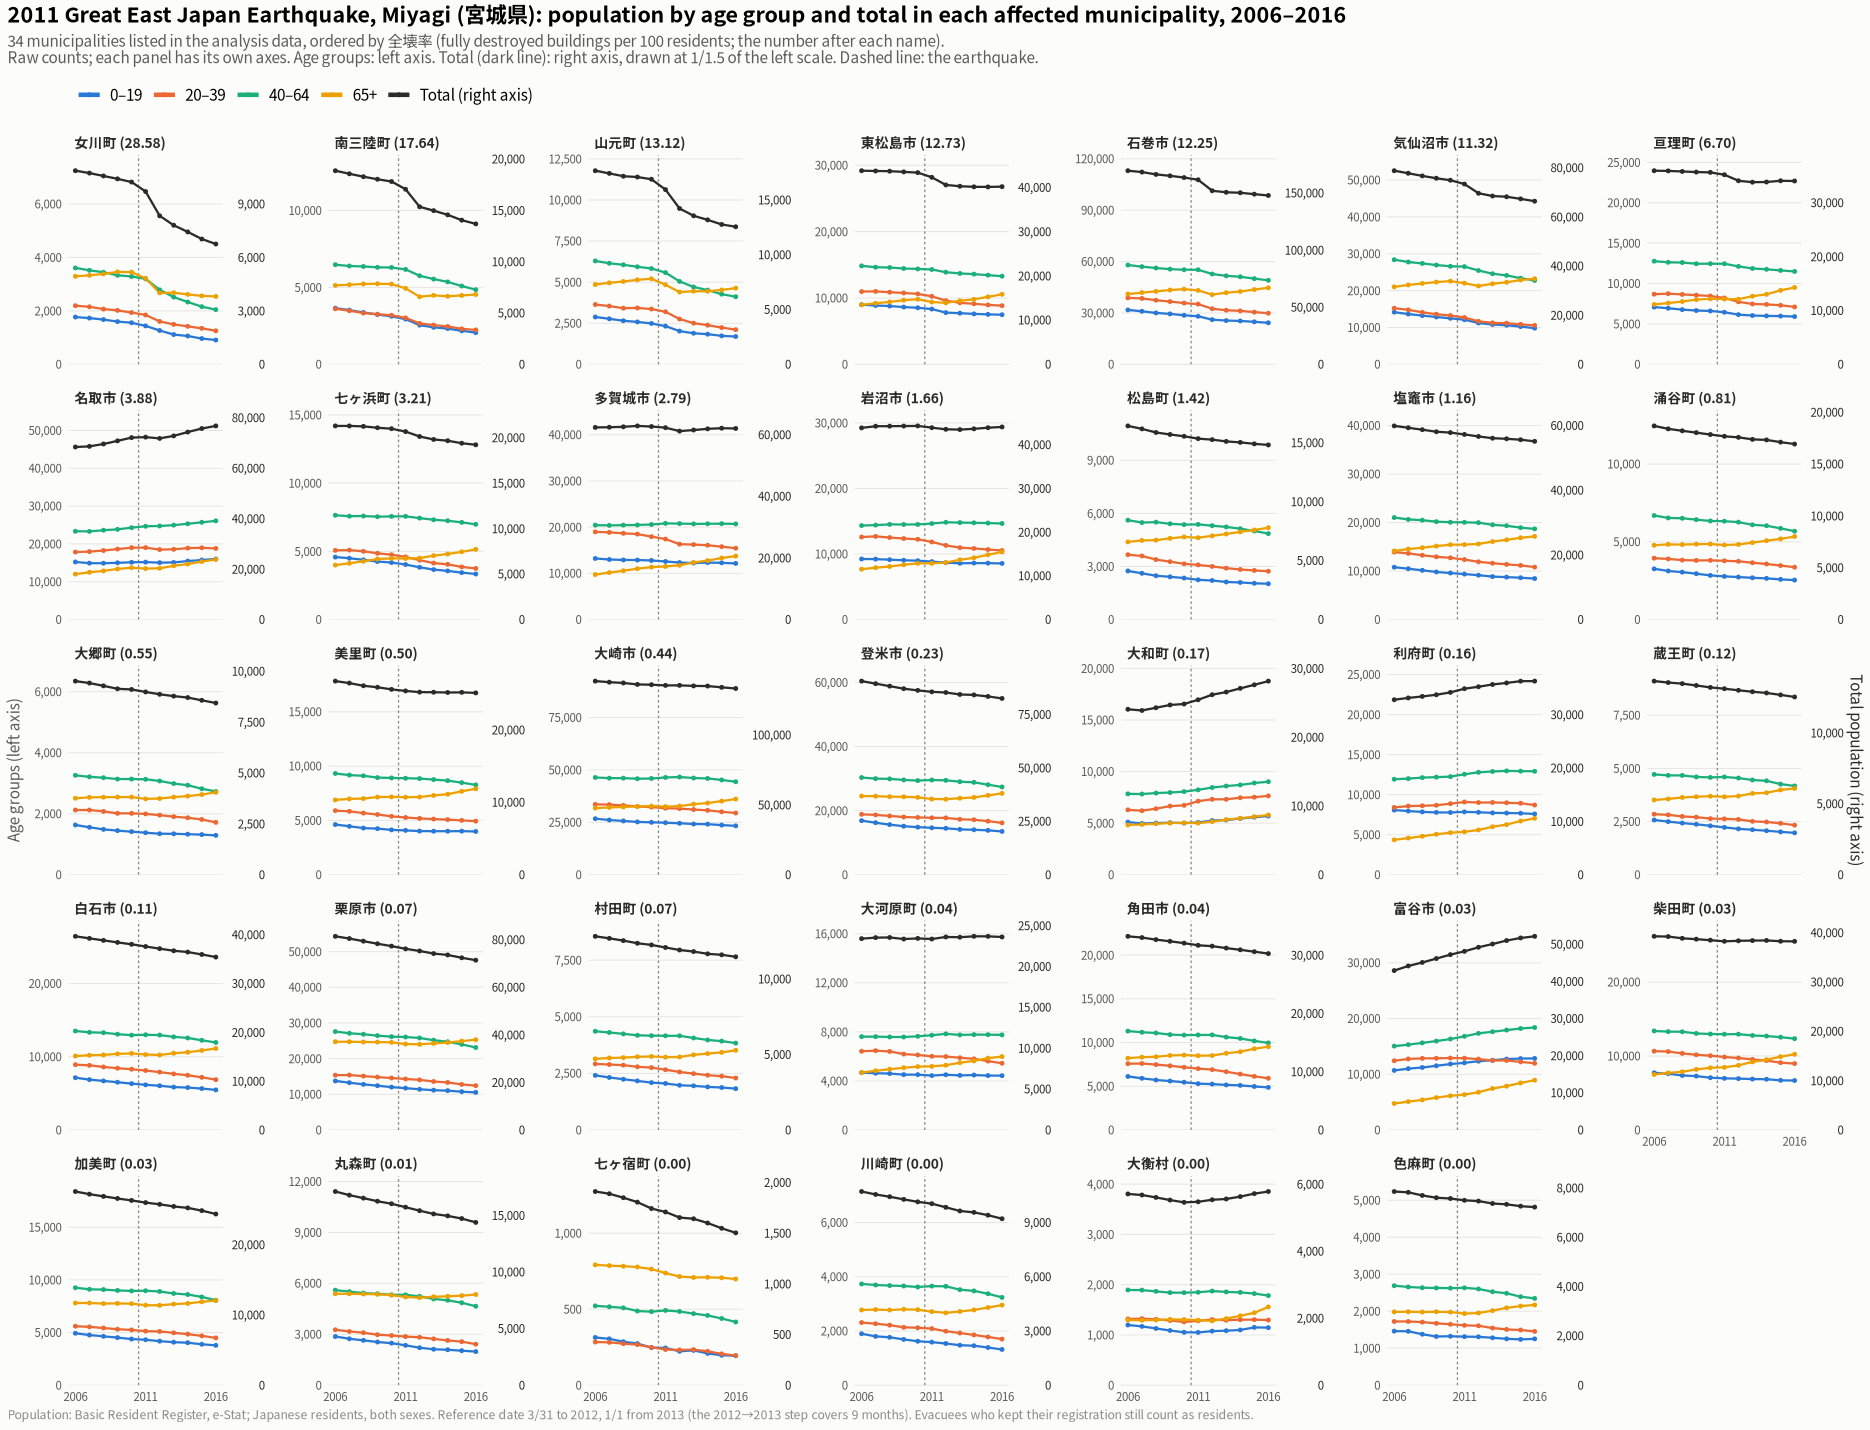

In [7]:
show_save(plot_facets("tohoku", "宮城県"), "03_miyagi_age_groups", width = 17, height = 11)

### Figure 4: Fukushima (福島県), 56 municipalities

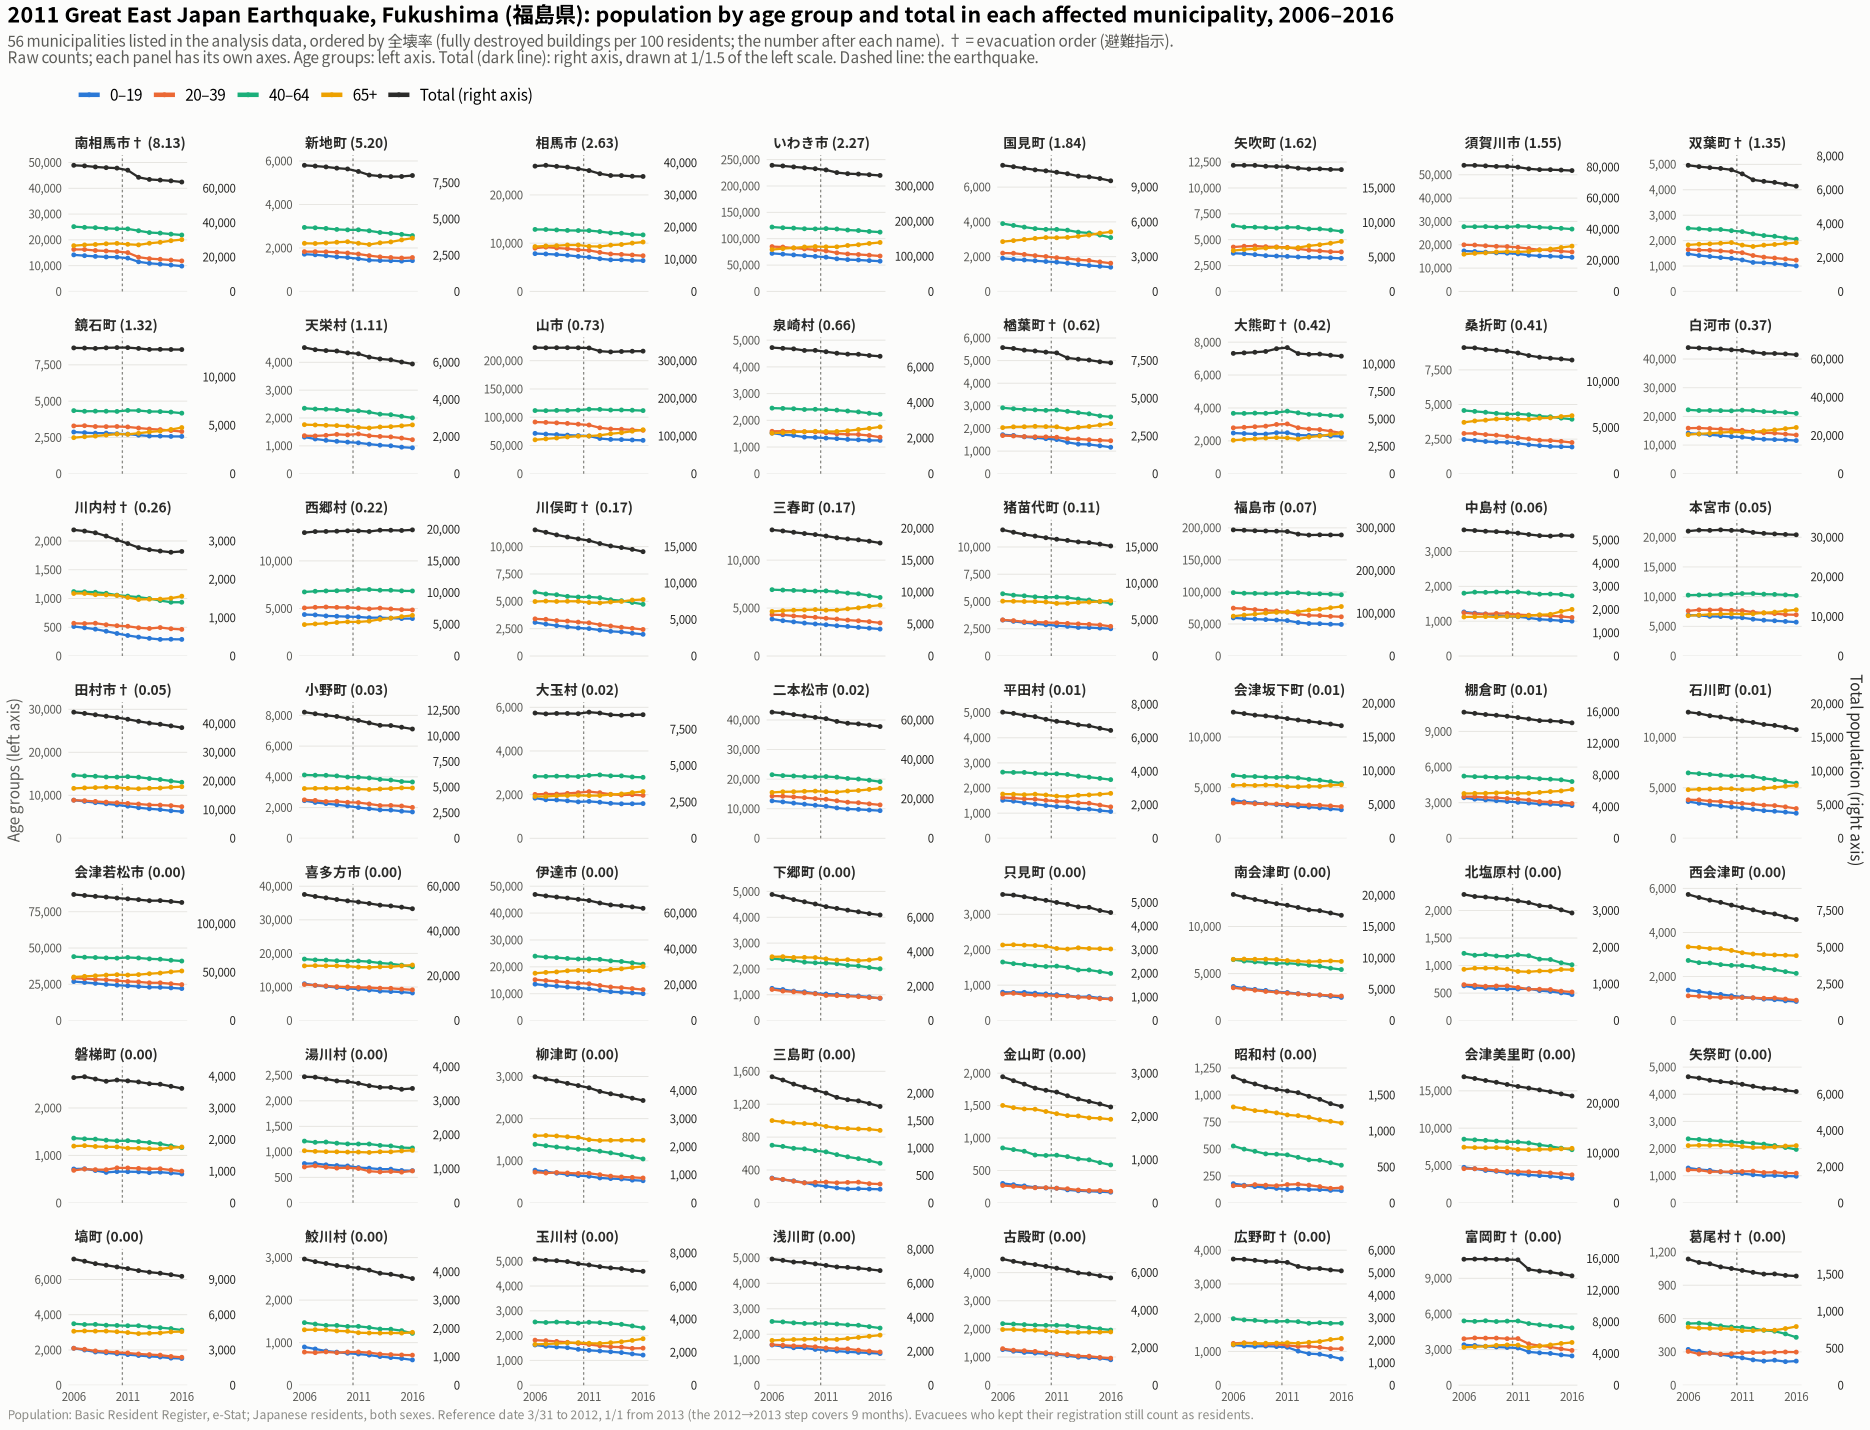

In [8]:
show_save(plot_facets("tohoku", "福島県", ncol = 8), "04_fukushima_age_groups", width = 19, height = 15)

## Year-on-year change rate

The same municipalities and age groups, shown as the % change in population from the previous year's count. Each point at year *t* is the change from *t*−1 to *t*.

- **Annualised:** counts moved from 31 March to 1 January in 2013, so the 2012→2013 step covers only 9 months. That step is annualised as `(P_t / P_t−1)^(1/0.75) − 1`, as in the protocol; the other years use plain `P_t / P_t−1 − 1`.
- **First year:** the first year of the window uses the count from the year before, so every year in the window has a rate.
- **Axes:** all series are percentages on one axis, with the total as the dark line. Each panel has its own y-axis, so a tsunami town's −20% doesn't flatten everyone else's ±2%. The grey line marks 0%.
- **Merger steps are blanked:** a municipality that absorbed neighbours, or was newly created, jumps or has no previous count. A total change above +5% in one year, or a missing previous count, is treated as a merger step: that year has no point for any group, and the steps are listed in a table. In Tohoku this is the 2005→2006 step for 27 municipalities (Heisei mergers before the 2006-03-31 count); Kumamoto has none.
- **Small groups are noisy:** in small villages an age group can be a few hundred people, so single-year rates of ±10% can come from a few dozen people moving.

In [9]:
# Year-on-year change rate per municipality and group. 2012-03-31 ->
# 2013-01-01 is 0.75 years; that step is annualised as in the protocol.
d_rate <- d_all |>
  group_by(code, group) |>
  arrange(year, .by_group = TRUE) |>
  mutate(span = ifelse(year == 2013, 0.75, 1),
         rate = 100 * ((pop / lag(pop))^(1 / span) - 1)) |>
  ungroup() |>
  filter(mapply(function(e, y) y %in% events[[e]]$years, event, year))

# Merger steps: a municipality that absorbed neighbours (or was newly created)
# shows a jump, or has no count for the previous year. Treat a total change
# above +5% (no real one-year change is that large here) or a missing previous
# count as a merger step, and blank that year's rates for every group.
merger_steps <- d_rate |>
  filter(group == "Total", is.na(rate) | rate > 5) |>
  select(event, code, muni, year, total_rate = rate)
d_rate <- d_rate |>
  left_join(merger_steps |> transmute(code, year, merger_step = TRUE), by = c("code", "year")) |>
  mutate(rate = ifelse(coalesce(merger_step, FALSE), NA_real_, rate),
         group = factor(group, levels = groups_all)) |>
  select(-merger_step)

# Steps blanked as mergers
merger_steps |> mutate(total_rate = round(total_rate, 1)) |> as.data.frame()

# Check: rates per event and group (blanked merger steps count as missing); range
d_rate |>
  group_by(event, group) |>
  summarise(n = n(), missing = sum(is.na(rate)),
            min = round(min(rate, na.rm = TRUE), 1),
            median = round(median(rate, na.rm = TRUE), 2),
            max = round(max(rate, na.rm = TRUE), 1), .groups = "drop") |>
  as.data.frame()

event,code,muni,year,total_rate
<chr>,<chr>,<chr>,<int>,<dbl>
tohoku,03202,宮古市,2006,13.3
tohoku,03205,花巻市,2006,46.0
tohoku,03207,久慈市,2006,8.2
tohoku,03208,遠野市,2006,18.1
tohoku,03209,一関市,2006,89.9
tohoku,03213,二戸市,2006,18.7
tohoku,03214,八幡平市,2006,NA
tohoku,03215,奥州市,2006,NA
tohoku,03366,和賀郡西和賀町,2006,NA


event,group,n,missing,min,median,max
<chr>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>
kumamoto,0–19,495,0,-8.9,-1.91,4.1
kumamoto,20–39,495,0,-12.8,-2.97,4.9
kumamoto,40–64,495,0,-7.2,-2.19,3.2
kumamoto,65+,495,0,-4.4,0.91,7.6
kumamoto,Total,495,0,-6.1,-1.25,2.7
tohoku,0–19,1353,27,-17.8,-2.65,4.6
tohoku,20–39,1353,27,-17.4,-2.04,7.6
tohoku,40–64,1353,27,-13.7,-1.19,4.9
tohoku,65+,1353,27,-20.3,0.99,13.3


In [10]:
plot_rate_facets <- function(e, pref_name, ncol = 7) {
  dr <- d_rate |> filter(event == e, pref == pref_name)
  lab <- panel_labels(dr)
  dr <- dr |> mutate(panel = factor(lab$label[match(code, lab$code)], levels = lab$label))
  ggplot(dr, aes(year, rate, colour = group, group = group)) +
    geom_hline(yintercept = 0, colour = "#8a8a85", linewidth = 0.4) +
    geom_vline(xintercept = events[[e]]$event_x, colour = "#8a8a85", linewidth = 0.4, linetype = "22") +
    geom_line(aes(linewidth = group == "Total"), na.rm = TRUE) +
    geom_point(size = 0.8, na.rm = TRUE) +
    facet_wrap(~panel, ncol = ncol, scales = "free_y") +
    scale_linewidth_manual(values = c(`FALSE` = 0.55, `TRUE` = 0.9), guide = "none") +
    scale_colour_manual(values = rate_cols, name = NULL) +
    x_scale(e) +
    scale_y_continuous(labels = function(v) sprintf("%+g%%", v),
                       expand = expansion(mult = 0.08)) +
    labs(
      title = fig_title(e, pref_name, "year-on-year population change by age group"),
      subtitle = paste0(nrow(lab), " municipalities listed in the analysis data, ordered by 全壊率 ",
                        "(the number after each name).",
                        if (any(lab$evacuation)) " † = evacuation order (避難指示)." else "",
                        " Point at year t = change from t−1 to t.\n",
                        "Each panel has its own y-axis; grey line = 0%. Dashed line: the earthquake (",
                        events[[e]]$rate_note, ")."),
      caption = paste0(source_note, "; the 2012→2013 change is annualised (9-month step)."),
      x = NULL, y = "Change from previous year (%, annualised)"
    ) +
    base_theme()
}

### Figure 5: Kumamoto (熊本県), year-on-year change rate

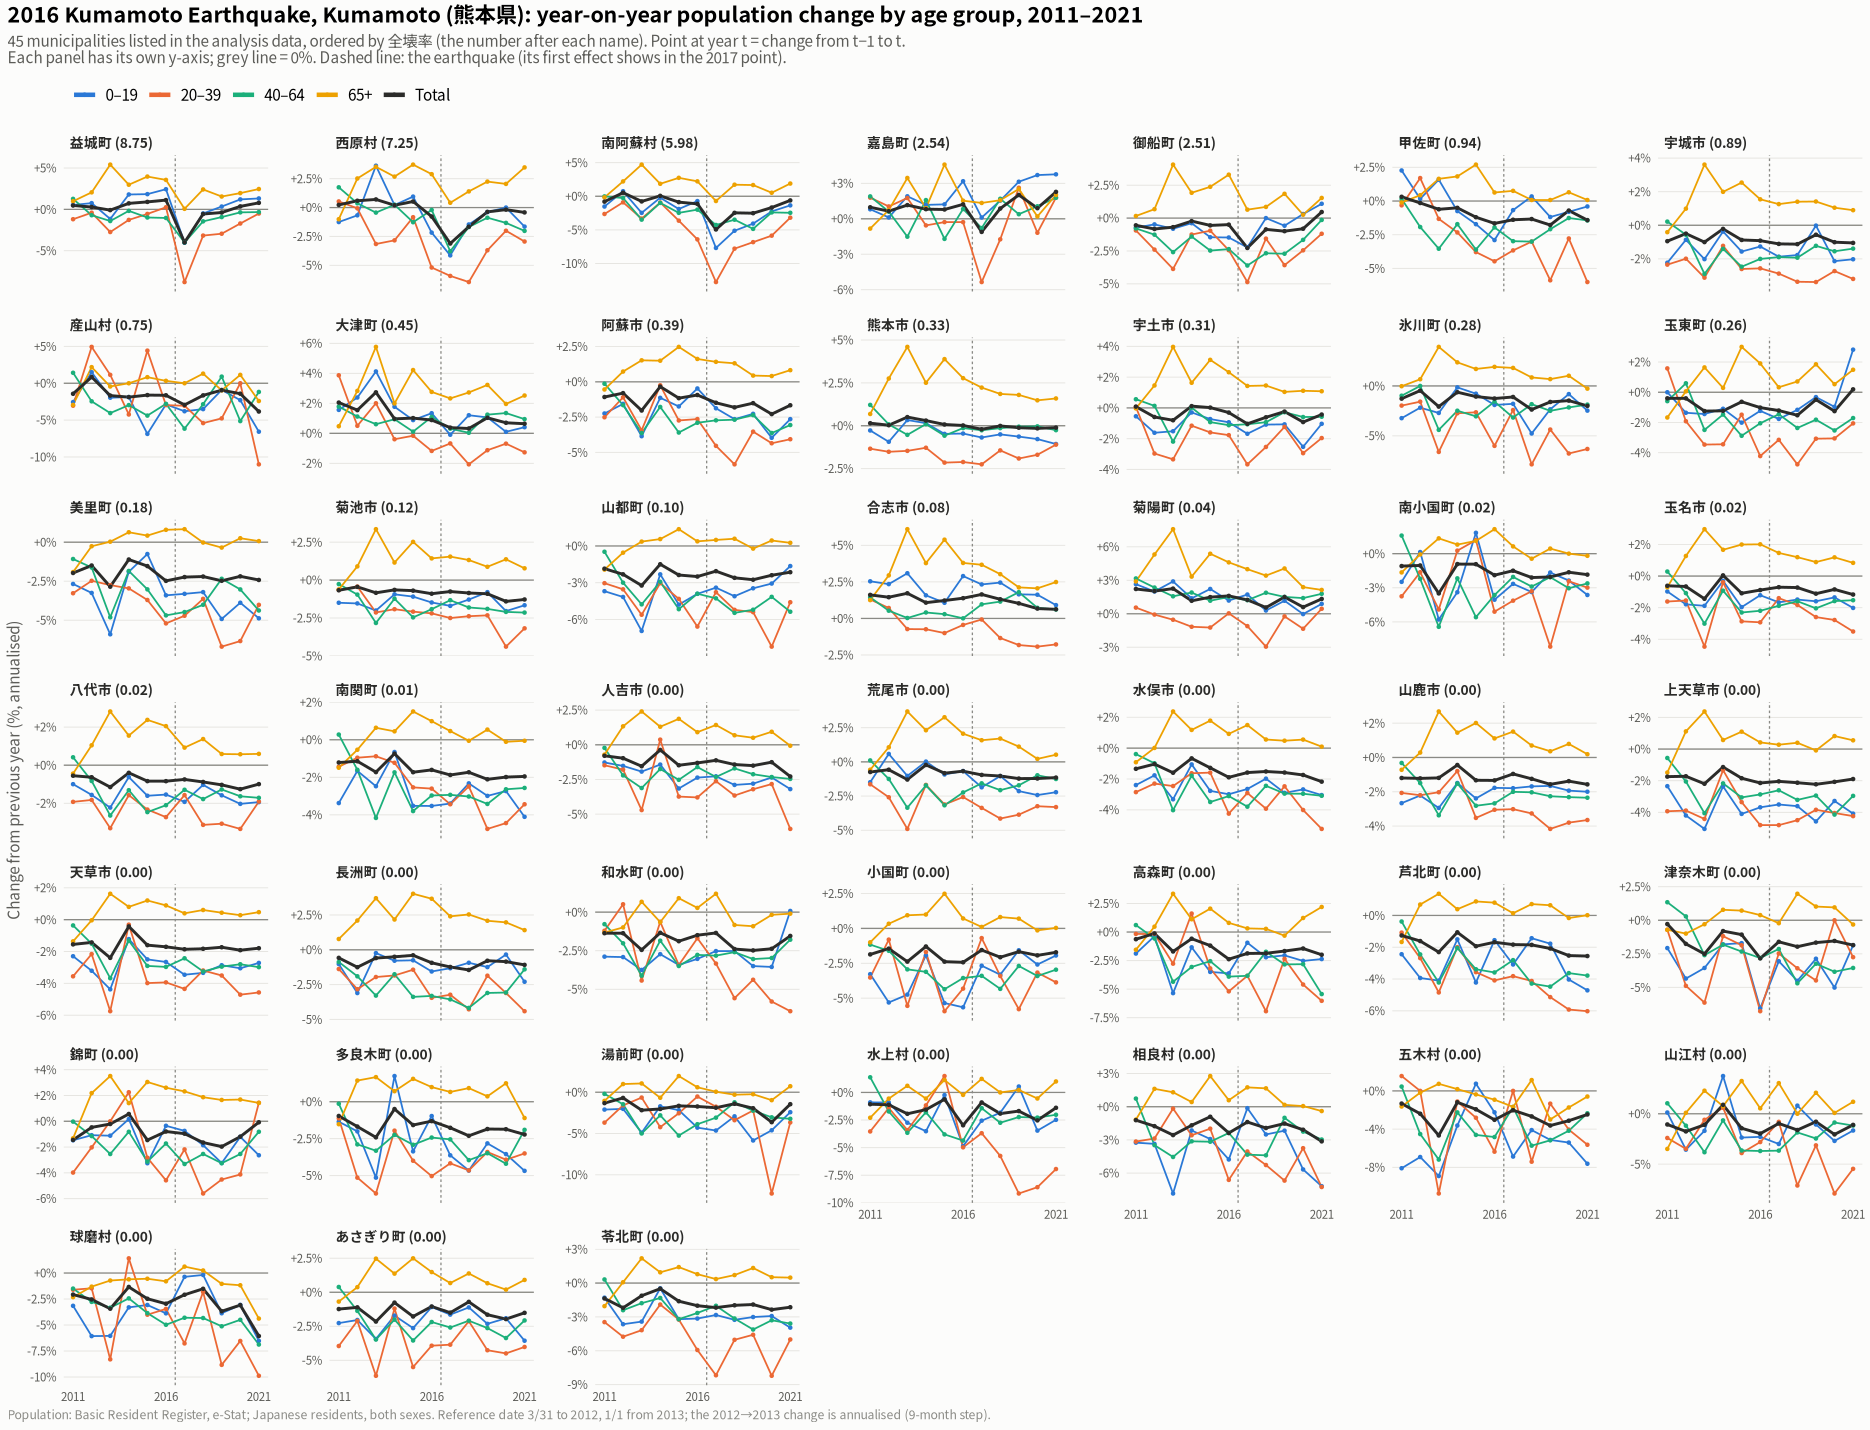

In [11]:
show_save(plot_rate_facets("kumamoto", "熊本県"), "05_kumamoto_change_rate", width = 17, height = 13)

### Figure 6: Iwate (岩手県), year-on-year change rate

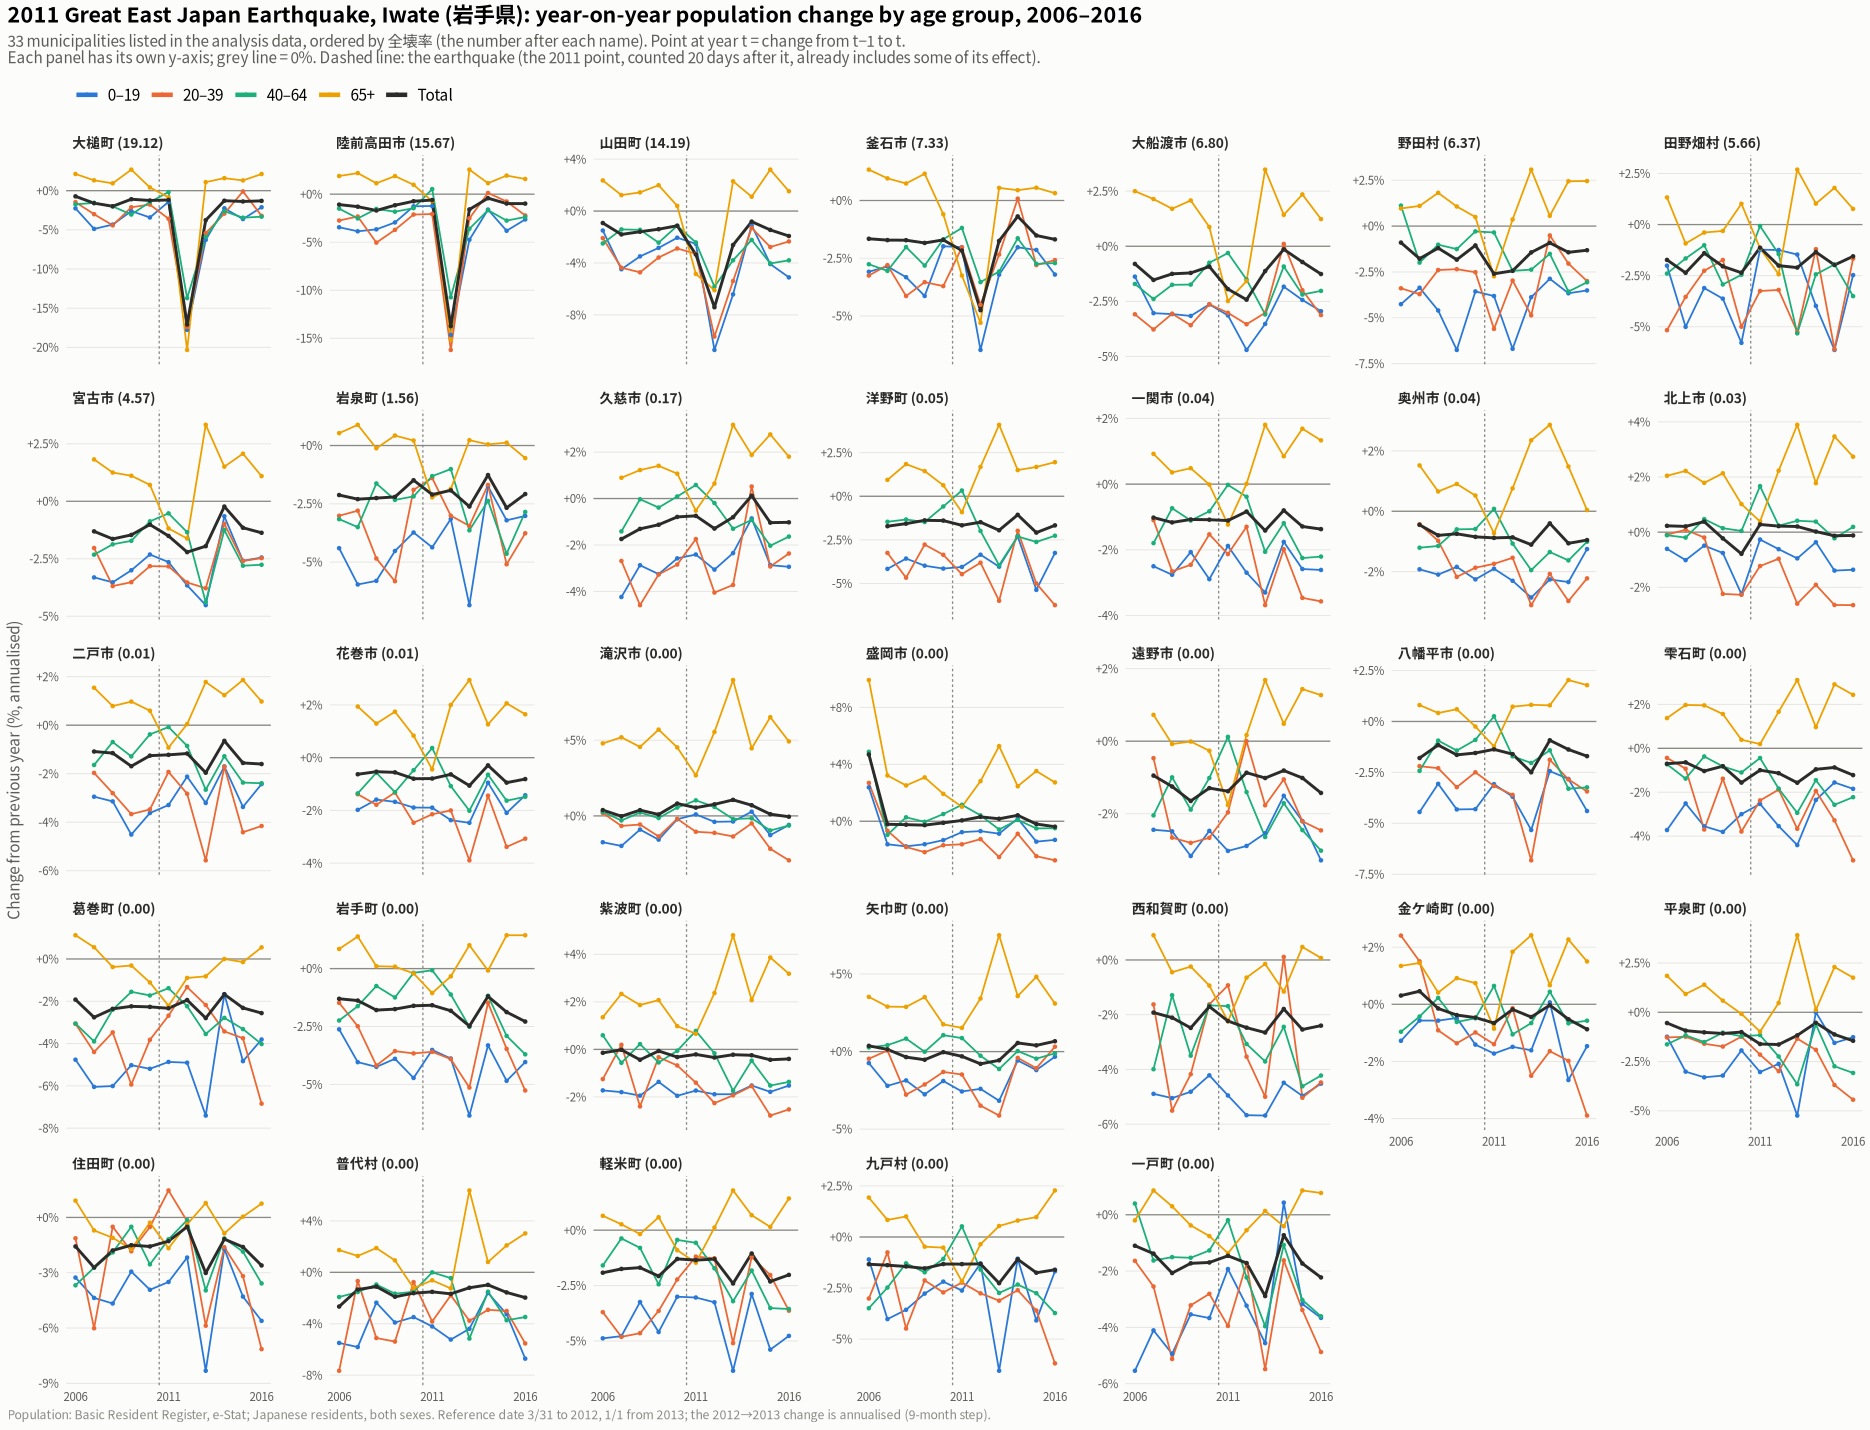

In [12]:
show_save(plot_rate_facets("tohoku", "岩手県"), "06_iwate_change_rate", width = 17, height = 11)

### Figure 7: Miyagi (宮城県), year-on-year change rate

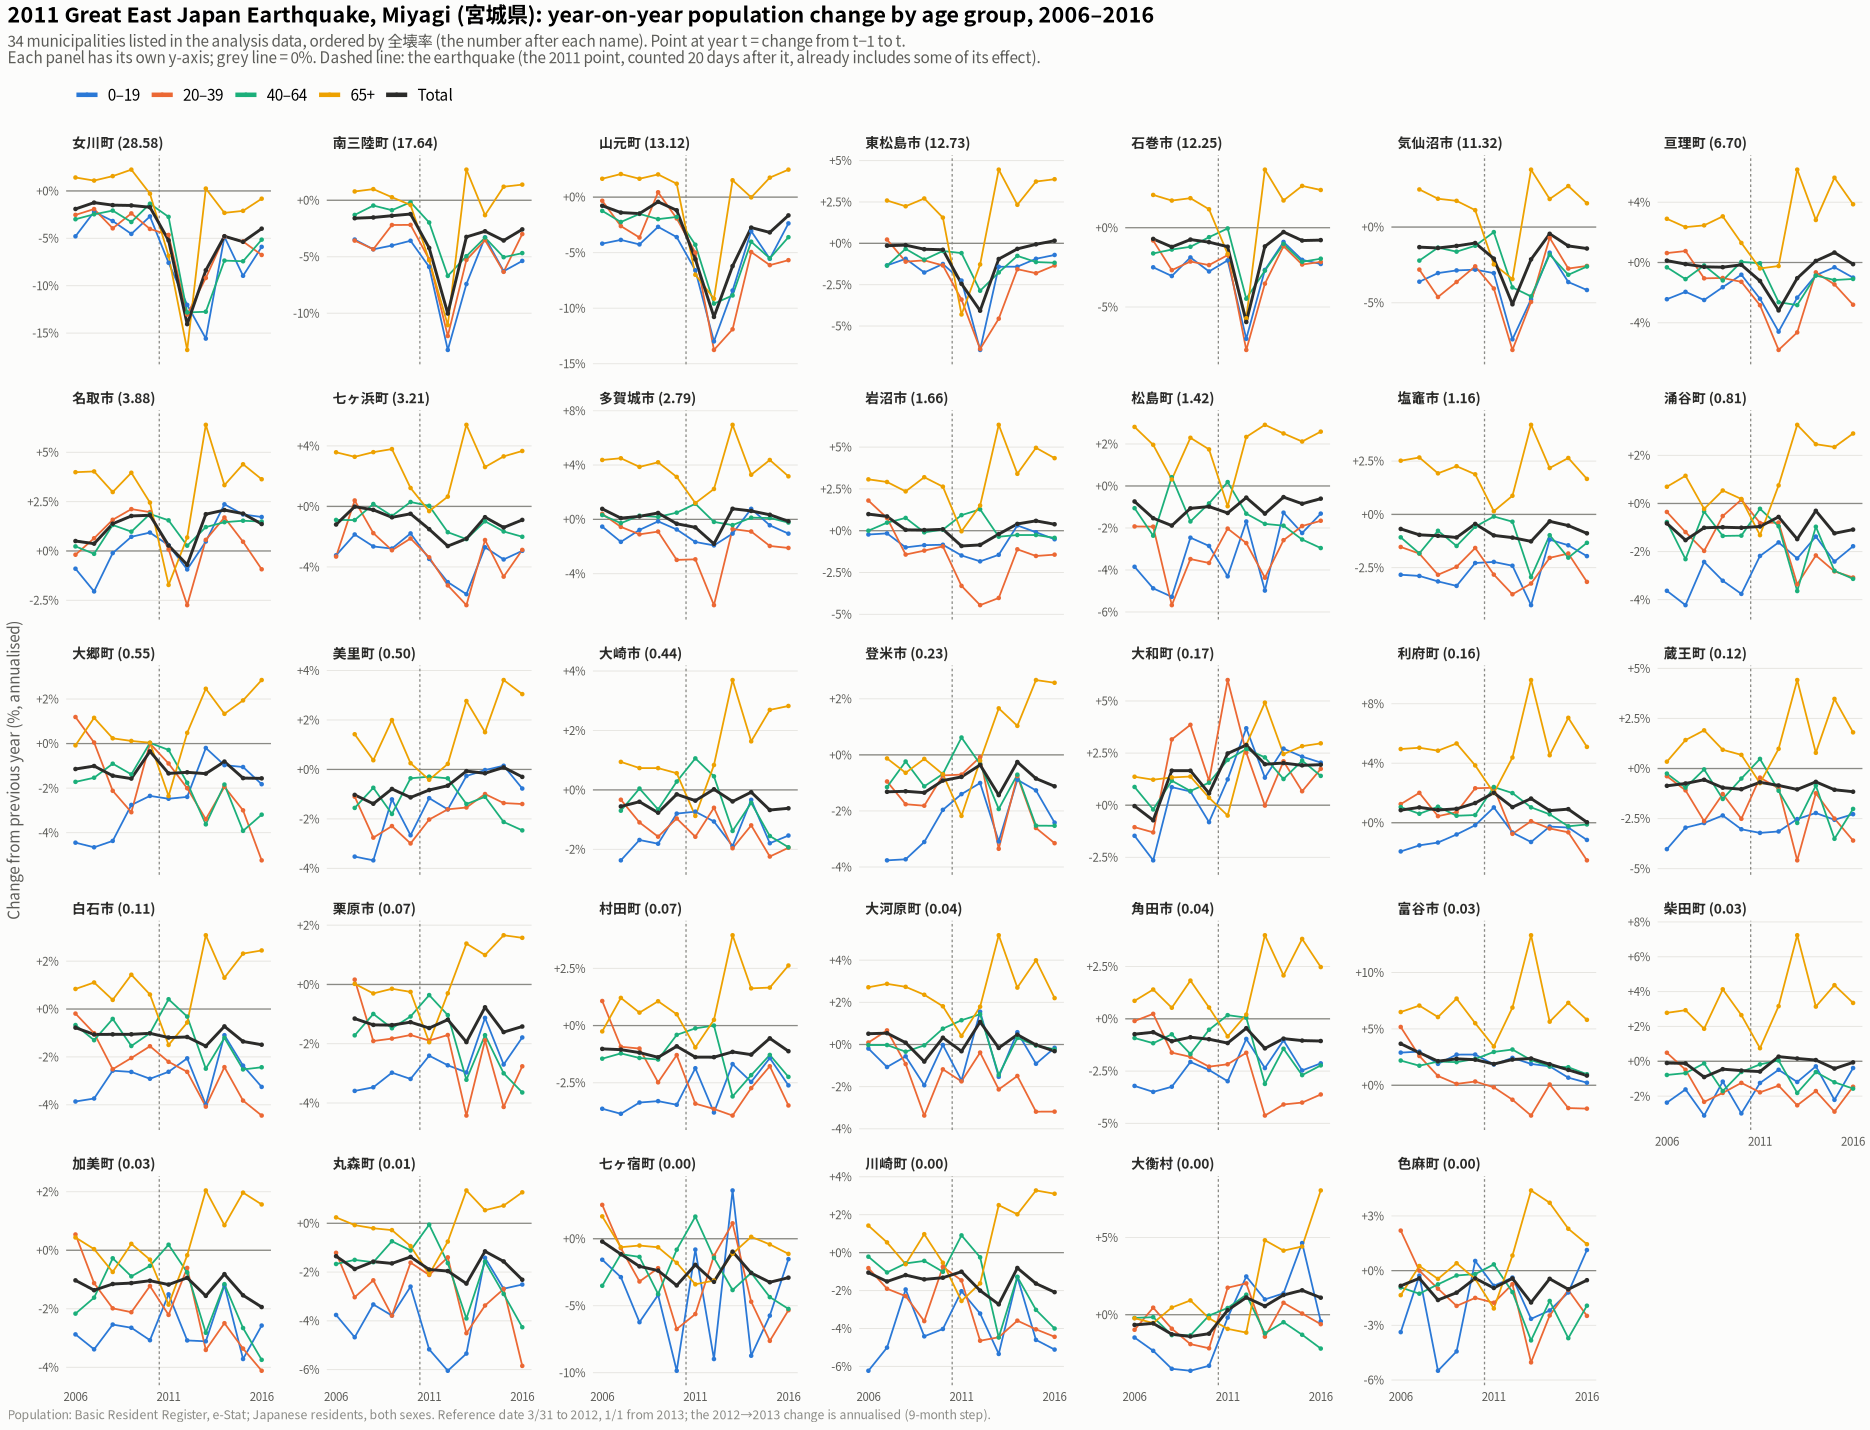

In [13]:
show_save(plot_rate_facets("tohoku", "宮城県"), "07_miyagi_change_rate", width = 17, height = 11)

### Figure 8: Fukushima (福島県), year-on-year change rate

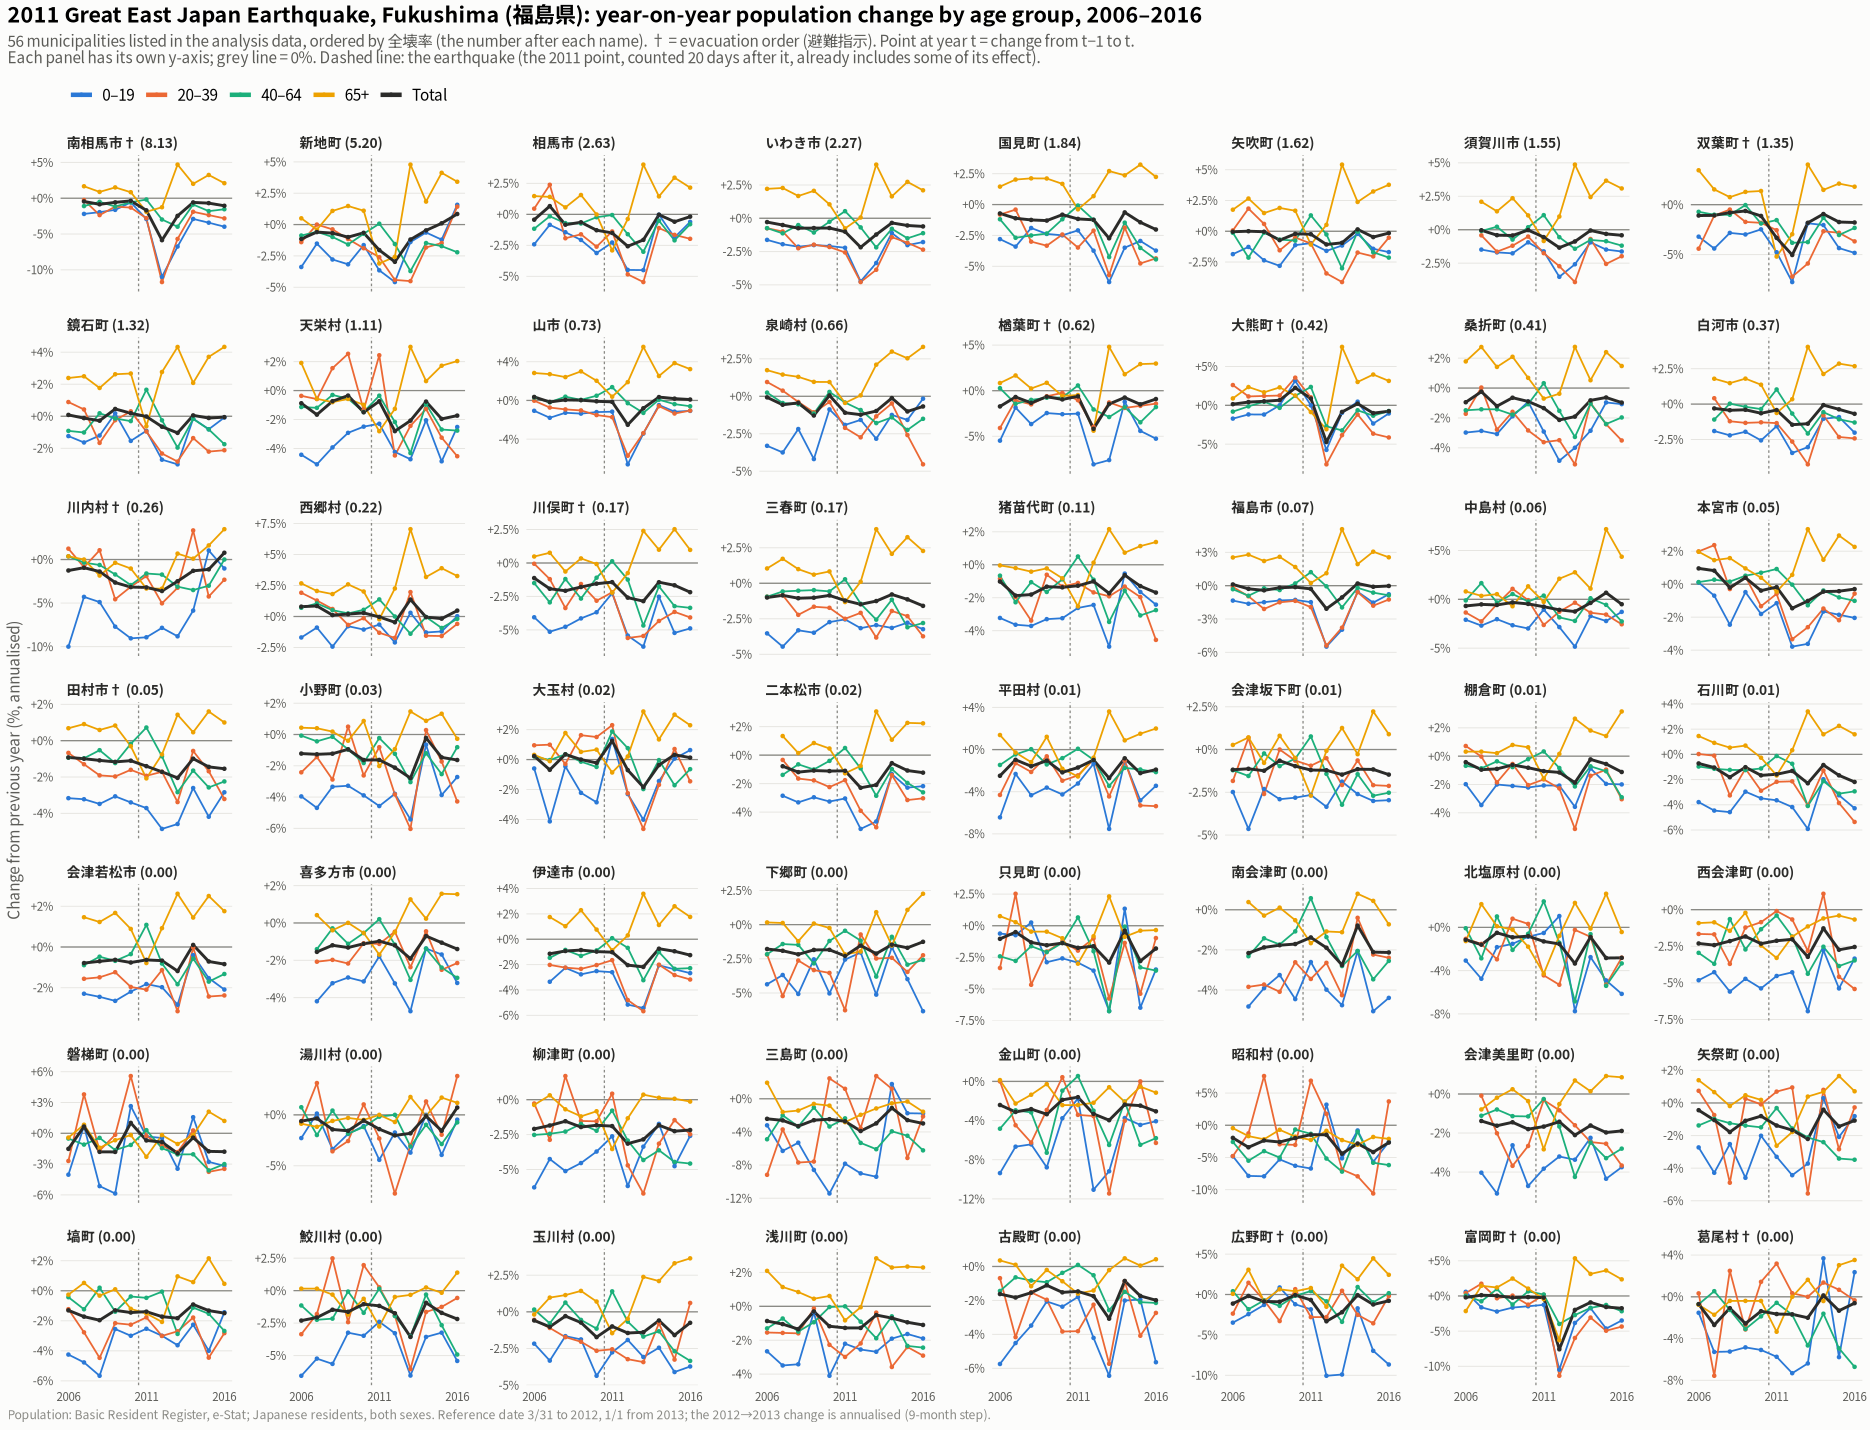

In [14]:
show_save(plot_rate_facets("tohoku", "福島県", ncol = 8), "08_fukushima_change_rate", width = 19, height = 15)